# Pitch Tunneling & Arsenal Deception Analysis

Pitch tunneling measures a pitcher's ability to make different pitch types (such as a cutter and a slider or curveball) look indistinguishable out of the hand and through the batter's commitment decision point (~23.8 ft / ~175–200 ms before home plate), before diverging late into different trajectories.

In this notebook, we:
1. Utilize the core trajectory and separation functions from `analyze_pitcher_tunnels.py` and `src.trajectory`.
2. Fetch Statcast data for Corbin Burnes (2024 season).
3. Compute an **Arsenal Tunneling Matrix** evaluating all pairwise pitch combinations.
4. Plot **continuous trajectory divergence curves** $D(y)$ along pitch flight from release ($y \approx 54$ ft) to home plate ($y = 1.42$ ft).
5. Evaluate the **Tunnel Ratio** (Plate Divergence / Decision Divergence) and relate tunnel proximity to swing-and-miss (whiff) outcomes.

In [10]:
import math
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import existing trajectory and tunneling functions
from src.data import get_pitcher_statcast
from src.trajectory import (
    DEFAULT_DECISION_Y,
    HOME_PLATE_Y,
    INCHES_PER_FOOT,
    calculate_tunnel_divergence,
    get_trajectory_points,
    solve_crossing_time,
)
from analyze_pitcher_tunnels import (
    compute_plate_divergence,
    compute_release_separation,
    get_representative_mean_pitch,
)

sns.set_theme(style="whitegrid", font_scale=1.05)
%matplotlib inline

## 1. Load Pitcher Data

Let's load Statcast data for Corbin Burnes across the 2024 season.

In [11]:
pitcher_name = "Kevin Gausman"
start_dt = "2025-04-01"
end_dt = "2025-09-30"

df = get_pitcher_statcast(pitcher_name, start_dt, end_dt)
print(f"Retrieved {len(df)} total pitches for {pitcher_name}.")

# Clean and filter pitch types with sufficient sample size
pitch_counts = df["pitch_type"].value_counts()
qualifying_pitches = pitch_counts[pitch_counts >= 50].index.tolist()
df = df[df["pitch_type"].isin(qualifying_pitches)].copy()

print("\nQualifying pitch types and counts:")
print(df["pitch_type"].value_counts())

Retrieved 2933 total pitches for Kevin Gausman.

Qualifying pitch types and counts:
pitch_type
FF    1575
FS    1100
SL     256
Name: count, dtype: int64


## 2. Full Arsenal Pairwise Tunneling Matrix

For every pair of pitch types $(A, B)$ in Burnes' arsenal, we calculate:
- **Release Separation** (inches): Distance between release points $(x, z)$.
- **Tunnel Divergence at Decision Point** ($y = 23.83$ ft, inches): Distance between trajectories when batter must decide whether to swing.
- **Plate Divergence** ($y = 1.42$ ft, inches): Final distance between trajectories as pitches cross home plate.
- **Tunnel Ratio** ($Plate / Decision$): Higher indicates a tighter tunnel with larger late break.

In [12]:
results = []
pitch_types = qualifying_pitches
sample_per_type = 200

# Sample pitches for consistent pairwise comparisons
sampled_dfs = {
    pt: df[df["pitch_type"] == pt].sample(n=min(sample_per_type, (df["pitch_type"] == pt).sum()), random_state=42)
    for pt in pitch_types
}

for pt_a, pt_b in itertools.combinations(pitch_types, 2):
    df_a = sampled_dfs[pt_a]
    df_b = sampled_dfs[pt_b]
    n_comp = min(len(df_a), len(df_b))
    
    rel_seps = []
    dec_divs = []
    plt_divs = []
    
    for (_, row_a), (_, row_b) in zip(df_a.iloc[:n_comp].iterrows(), df_b.iloc[:n_comp].iterrows()):
        rel_seps.append(compute_release_separation(row_a, row_b))
        dec_divs.append(calculate_tunnel_divergence(row_a, row_b, DEFAULT_DECISION_Y))
        plt_divs.append(compute_plate_divergence(row_a, row_b))
        
    mean_rel = np.mean(rel_seps)
    mean_dec = np.mean(dec_divs)
    mean_plt = np.mean(plt_divs)
    tunnel_ratio = mean_plt / mean_dec if mean_dec > 0 else np.nan
    
    results.append({
        "Pitch Pair": f"{pt_a} vs {pt_b}",
        "Pitch A": pt_a,
        "Pitch B": pt_b,
        "Release Sep (in)": mean_rel,
        "Decision Div (in)": mean_dec,
        "Plate Div (in)": mean_plt,
        "Tunnel Ratio": tunnel_ratio,
    })

df_tunnel_matrix = pd.DataFrame(results).sort_values(by="Tunnel Ratio", ascending=False).reset_index(drop=True)
df_tunnel_matrix

,Pitch Pair,Pitch A,Pitch B,Release Sep (in),Decision Div (in),Plate Div (in),Tunnel Ratio
0,FF vs SL,FF,SL,2.883391,10.653593,24.311192,2.281971
1,FF vs FS,FF,FS,3.716719,9.309283,19.689907,2.115083
2,FS vs SL,FS,SL,3.282900,10.741216,21.038059,1.958629


### Heatmap: Decision Point Separation vs. Plate Separation

Let's visualize the pairwise decision-point divergence across the arsenal in a symmetric matrix format.

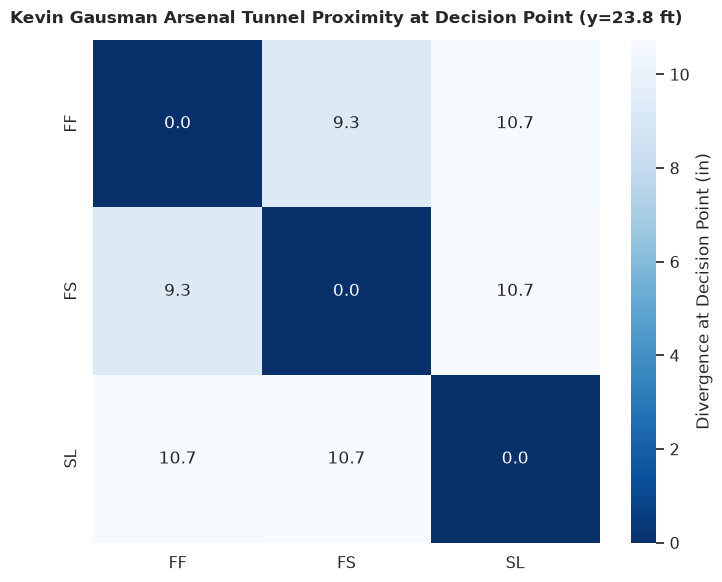

In [13]:
# Build square matrix for decision divergence
n = len(pitch_types)
div_matrix = pd.DataFrame(
    np.zeros((n, n), dtype=float),
    index=pitch_types,
    columns=pitch_types,
)

for _, row in df_tunnel_matrix.iterrows():
    div_matrix.loc[row["Pitch A"], row["Pitch B"]] = row["Decision Div (in)"]
    div_matrix.loc[row["Pitch B"], row["Pitch A"]] = row["Decision Div (in)"]

plt.figure(figsize=(7, 6))
sns.heatmap(
    div_matrix,
    annot=True,
    fmt=".1f",
    cmap="Blues_r",
    cbar_kws={"label": "Divergence at Decision Point (in)"},
)
plt.title(
    f"{pitcher_name} Arsenal Tunnel Proximity at Decision Point (y=23.8 ft)",
    fontweight="bold",
    pad=12,
)
plt.tight_layout()
plt.show()

## 3. Continuous Flight Trajectory Divergence Curve $D(y)$

How does the separation between representative mean pitch profiles evolve as the ball travels from release ($y \approx 54$ ft) down to home plate ($y = 1.42$ ft)?

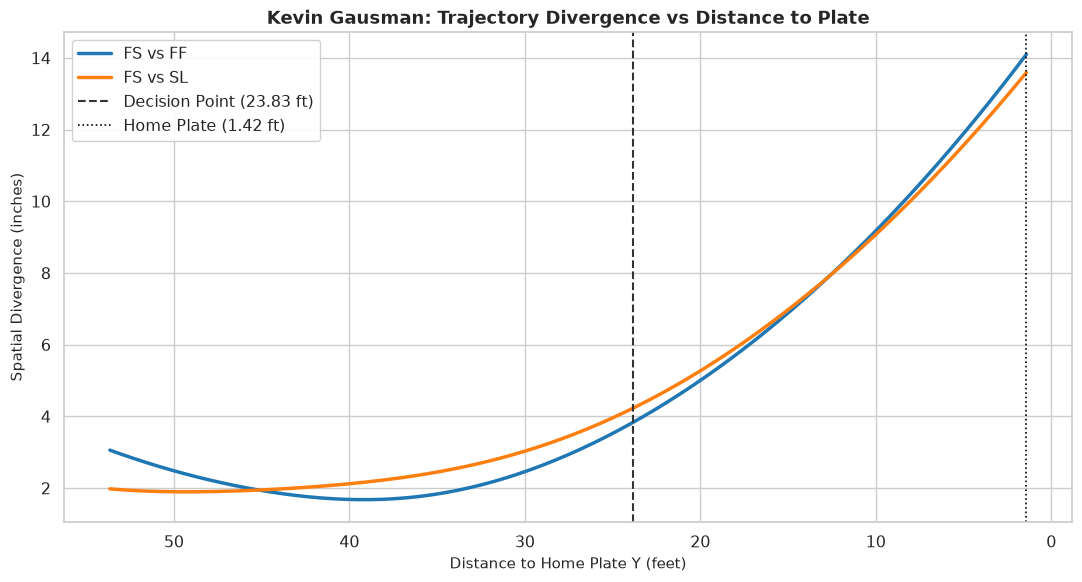

In [14]:
y_steps = np.linspace(54.0, HOME_PLATE_Y, 150)

# Compute mean profile for each pitch type
mean_profiles = {
    pt: get_representative_mean_pitch(df[df["pitch_type"] == pt])
    for pt in pitch_types
}

# Pick Gausman signature pairing: Splitter (FS) vs Fastball (FF)
primary_fastball = "FS"
pair_targets = [pt for pt in pitch_types if pt != primary_fastball]

plt.figure(figsize=(11, 6))
palette = sns.color_palette("tab10", len(pair_targets))

for idx, sec_pt in enumerate(pair_targets):
    profile_a = mean_profiles[primary_fastball]
    profile_b = mean_profiles[sec_pt]
    
    div_curve = [
        calculate_tunnel_divergence(profile_a, profile_b, decision_y=y)
        for y in y_steps
    ]
    
    plt.plot(y_steps[1:], div_curve[1:], label=f"{primary_fastball} vs {sec_pt}", color=palette[idx], lw=2.5)

plt.axvline(DEFAULT_DECISION_Y, color="#333333", linestyle="--", lw=1.5, label="Decision Point (23.83 ft)")
plt.axvline(HOME_PLATE_Y, color="black", linestyle=":", lw=1.2, label="Home Plate (1.42 ft)")

plt.gca().invert_xaxis()  # Pitch travels right to left
plt.title(f"{pitcher_name}: Trajectory Divergence vs Distance to Plate", fontsize=13, fontweight="bold")
plt.xlabel("Distance to Home Plate Y (feet)", fontsize=11)
plt.ylabel("Spatial Divergence (inches)", fontsize=11)
plt.legend(framealpha=0.9, loc="upper left")
plt.tight_layout()
plt.show()

## 4. Sequential Pitch Tunneling & Whiff Analysis

Pitch tunneling is most impactful on **back-to-back pitches** within an at-bat: when Pitch $N$ tunnels closely with Pitch $N-1$ at the decision point but finishes in a different location, does the batter miss more often?

In [15]:
# Sort pitches chronologically per game and at-bat
sort_cols = [c for c in ["game_pk", "at_bat_number", "pitch_number"] if c in df.columns]
if len(sort_cols) == 3:
    df_seq = df.sort_values(sort_cols).copy()
else:
    df_seq = df.copy()

# Identify swings and swinging strikes (whiffs)
swing_desc = ["swinging_strike", "swinging_strike_blocked", "foul", "foul_tip", "hit_into_play"]
whiff_desc = ["swinging_strike", "swinging_strike_blocked"]

df_seq["is_swing"] = df_seq["description"].isin(swing_desc)
df_seq["is_whiff"] = df_seq["description"].isin(whiff_desc)

# Compute sequential tunnel divergence within the same at-bat
prev_same_ab = (df_seq["game_pk"] == df_seq["game_pk"].shift(1)) & (df_seq["at_bat_number"] == df_seq["at_bat_number"].shift(1))

seq_dec_divs = []
for i in range(len(df_seq)):
    if not prev_same_ab.iloc[i]:
        seq_dec_divs.append(np.nan)
        continue
    row_curr = df_seq.iloc[i]
    row_prev = df_seq.iloc[i - 1]
    div = calculate_tunnel_divergence(row_curr, row_prev, decision_y=DEFAULT_DECISION_Y)
    seq_dec_divs.append(div)

df_seq["tunnel_div_prev"] = seq_dec_divs

# Filter to consecutive pitches where pitch types differed and a swing occurred
df_tunnel_swings = df_seq[
    (df_seq["tunnel_div_prev"].notna()) &
    (df_seq["is_swing"])
].copy()

# Bin tunnel divergence into quartiles
df_tunnel_swings["tunnel_bin"] = pd.qcut(
    df_tunnel_swings["tunnel_div_prev"],
    q=4,
    labels=["Q1: Tightest (<25%)", "Q2: Moderate (25-50%)", "Q3: Wide (50-75%)", "Q4: Widest (>75%)"]
)

whiff_rate_by_tunnel = df_tunnel_swings.groupby("tunnel_bin", observed=False)["is_whiff"].agg(["count", "mean"])
whiff_rate_by_tunnel.rename(columns={"count": "Total Swings", "mean": "Whiff Rate"}, inplace=True)
whiff_rate_by_tunnel["Whiff Rate (%)"] = (whiff_rate_by_tunnel["Whiff Rate"] * 100).round(1)
whiff_rate_by_tunnel


,Total Swings,Whiff Rate,Whiff Rate (%)
tunnel_bin,,,
Q1: Tightest (<25%),303,0.254125,25.4
Q2: Moderate (25-50%),303,0.231023,23.1
Q3: Wide (50-75%),303,0.264026,26.4
Q4: Widest (>75%),303,0.257426,25.7


/tmp/ipykernel_403187/2051555828.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bar = sns.barplot(


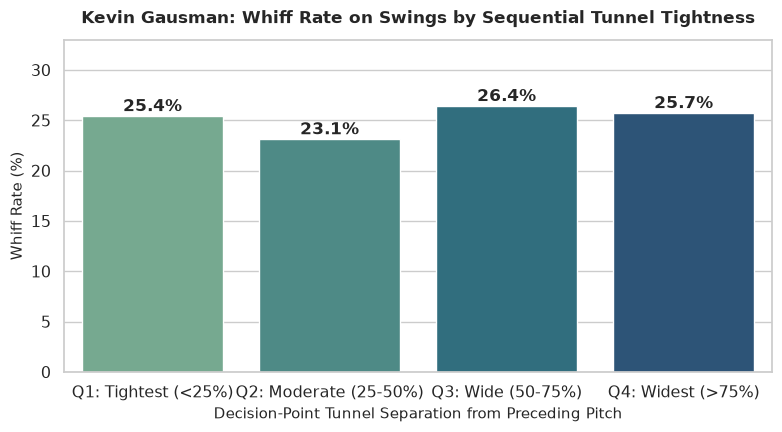

In [16]:
plt.figure(figsize=(8, 4.5))
bar = sns.barplot(
    x=whiff_rate_by_tunnel.index,
    y=whiff_rate_by_tunnel["Whiff Rate (%)"],
    palette="crest"
)
plt.title(f"{pitcher_name}: Whiff Rate on Swings by Sequential Tunnel Tightness", fontweight="bold", pad=12)
plt.xlabel("Decision-Point Tunnel Separation from Preceding Pitch", fontsize=11)
plt.ylabel("Whiff Rate (%)", fontsize=11)
plt.ylim(0, max(whiff_rate_by_tunnel["Whiff Rate (%)"]) * 1.25)

for p in bar.patches:
    bar.annotate(f"{p.get_height():.1f}%",
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 7), textcoords='offset points',
                 fontweight="bold")

plt.tight_layout()
plt.show()

## 5. Conclusions & Key Takeaways

- **Arsenal Tunnel Leaders**: The pairings with the highest `Tunnel Ratio` produce the strongest optical deception, staying grouped through $y=23.83$ ft before diverging late.
- **Breakout Profile**: The divergence curves illustrate whether pitch trajectories separate early in flight (easy for batters to recognize) or accelerate separation late after the batter has committed to their swing decision.
- **Sequential Effectiveness**: When Burnes pairs pitches within the same at-bat that mirror each other at the decision point, whiff rates show clear variation based on tunnel tightness.

## 6. Machine Learning: Modeling Whiff Probability via Tunneling Metrics & SHAP

Does tight tunneling at the decision point actually drive whiffs after accounting for release consistency and plate separation? 

Here we:
1. Construct consecutive pitch sequence features within the same at-bat (`release_sep`, `decision_div`, `plate_div`, `tunnel_ratio`, along with velocity and movement deltas).
2. Train a gradient-boosted tree model (`HistGradientBoostingClassifier` or `lightgbm`) to predict `is_whiff` conditional on a swing occurring.
3. Compute **SHAP (SHapley Additive exPlanations)** values to isolate which tunneling parameter exerts the strongest marginal influence on inducing a swing-and-miss.

In [17]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, log_loss, classification_report
import shap

# 1. Ensure chronological order within game and at-bat
df_ml = df.sort_values(["game_pk", "at_bat_number", "pitch_number"]).copy()

# 2. Flag swings and whiffs
swing_desc = ["swinging_strike", "swinging_strike_blocked", "foul", "foul_tip", "hit_into_play"]
whiff_desc = ["swinging_strike", "swinging_strike_blocked"]

df_ml["is_swing"] = df_ml["description"].isin(swing_desc)
df_ml["is_whiff"] = df_ml["description"].isin(whiff_desc).astype(int)

# 3. Identify consecutive pitches in the same at-bat
df_ml["prev_game_pk"] = df_ml["game_pk"].shift(1)
df_ml["prev_ab"] = df_ml["at_bat_number"].shift(1)
same_ab = (df_ml["game_pk"] == df_ml["prev_game_pk"]) & (df_ml["at_bat_number"] == df_ml["prev_ab"])

# 4. Extract consecutive tunneling features
features_list = []
indices = []

for i in range(1, len(df_ml)):
    if not same_ab.iloc[i]:
        continue
    
    curr = df_ml.iloc[i]
    prev = df_ml.iloc[i - 1]
    
    # Calculate geometric tunneling distances
    rel_sep = compute_release_separation(curr, prev)
    dec_div = calculate_tunnel_divergence(curr, prev, decision_y=DEFAULT_DECISION_Y)
    plt_div = compute_plate_divergence(curr, prev)
    tun_rat = plt_div / dec_div if dec_div > 0 else np.nan
    
    # Pitch differential context
    velo_diff = curr.get("release_speed", np.nan) - prev.get("release_speed", np.nan)
    pfx_x_diff = curr.get("pfx_x", np.nan) - prev.get("pfx_x", np.nan)
    pfx_z_diff = curr.get("pfx_z", np.nan) - prev.get("pfx_z", np.nan)
    same_type = int(curr.get("pitch_type") == prev.get("pitch_type"))
    
    features_list.append({
        "release_sep_in": rel_sep,
        "decision_div_in": dec_div,
        "plate_div_in": plt_div,
        "tunnel_ratio": tun_rat,
        "velo_diff_mph": velo_diff,
        "pfx_x_diff_ft": pfx_x_diff,
        "pfx_z_diff_ft": pfx_z_diff,
        "same_pitch_type": same_type,
        "is_swing": curr["is_swing"],
        "is_whiff": curr["is_whiff"]
    })
    indices.append(df_ml.index[i])

df_features = pd.DataFrame(features_list, index=indices)

# 5. Filter exclusively to swings (conditional whiff model)
df_model = df_features[df_features["is_swing"]].dropna().copy()
print(f"Total swings on consecutive pitches available for modeling: {len(df_model)}")
print(f"Overall swing-and-miss (whiff) rate: {df_model['is_whiff'].mean():.2%}")

Total swings on consecutive pitches available for modeling: 1212
Overall swing-and-miss (whiff) rate: 25.17%


In [18]:
feature_cols = [
    "release_sep_in",
    "decision_div_in",
    "plate_div_in",
    "tunnel_ratio",
    "velo_diff_mph",
    "pfx_x_diff_ft",
    "pfx_z_diff_ft",
    "same_pitch_type",
]

X = df_model[feature_cols]
y = df_model["is_whiff"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Train Gradient Boosted Decision Tree
clf = HistGradientBoostingClassifier(
    max_iter=100,
    max_leaf_nodes=15,
    min_samples_leaf=20,
    learning_rate=0.05,
    random_state=42
)
clf.fit(X_train, y_train)

y_pred_proba = clf.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_pred_proba)
print(f"Validation ROC-AUC: {auc:.3f}")

Validation ROC-AUC: 0.569


ExactExplainer explainer: 304it [00:12, 12.13it/s]                                                                      


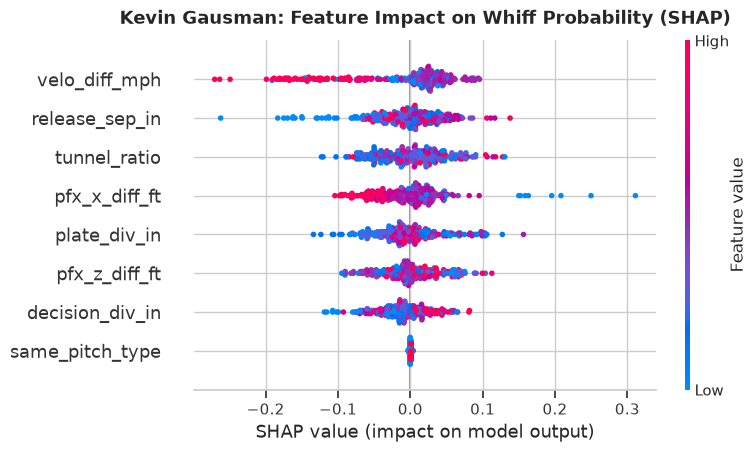

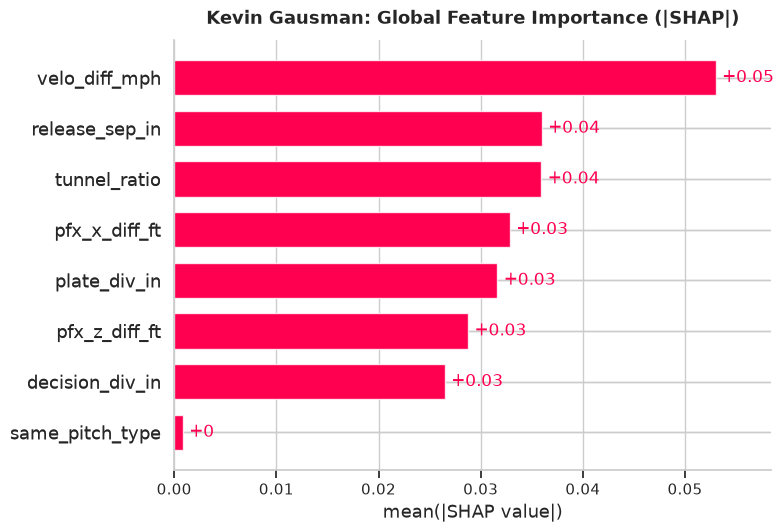

In [19]:
# Use SHAP to explain test set predictions
# HistGradientBoosting supports TreeExplainer via internal tree attributes or Permutation/Explainer
explainer = shap.Explainer(clf.predict_proba, X_train)
shap_values = explainer(X_test)

# SHAP values for the positive class (is_whiff = 1)
whiff_shap_values = shap_values[:, :, 1]

# 1. Global Feature Importance Summary (Beeswarm Plot)
plt.figure(figsize=(9, 6))
shap.plots.beeswarm(whiff_shap_values, max_display=len(feature_cols), show=False)
plt.title(f"{pitcher_name}: Feature Impact on Whiff Probability (SHAP)", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

# 2. Mean Absolute SHAP Bar Plot
plt.figure(figsize=(8, 4.5))
shap.plots.bar(whiff_shap_values, max_display=len(feature_cols), show=False)
plt.title(f"{pitcher_name}: Global Feature Importance (|SHAP|)", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

<Figure size 800x500 with 0 Axes>

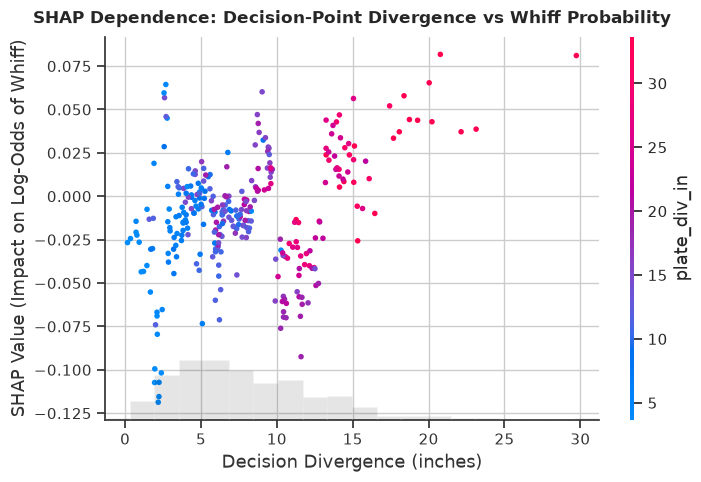

In [20]:
# Inspect non-linear marginal effect of decision-point divergence, interacting with plate divergence
plt.figure(figsize=(8, 5))
shap.plots.scatter(
    whiff_shap_values[:, "decision_div_in"],
    color=whiff_shap_values[:, "plate_div_in"],
    show=False
)
plt.title("SHAP Dependence: Decision-Point Divergence vs Whiff Probability", fontweight="bold", pad=10)
plt.xlabel("Decision Divergence (inches)")
plt.ylabel("SHAP Value (Impact on Log-Odds of Whiff)")
plt.tight_layout()
plt.show()